<a href="https://colab.research.google.com/github/LGLV-Ciencia-de-Datos/Bioinformatics_DCA/blob/master/U3_Cuaderno3_Metabolomica_y_Analisis_Multivariado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

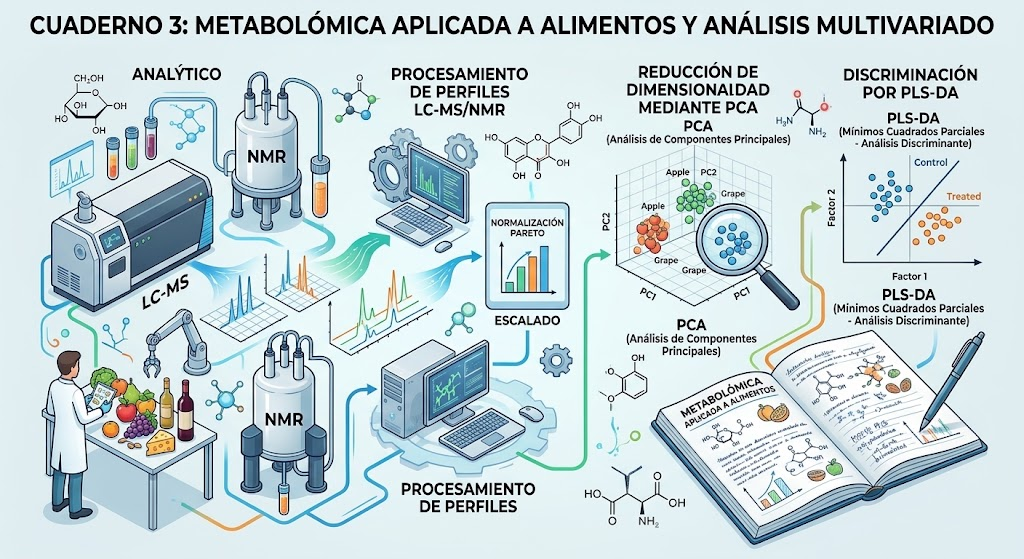

# Cuaderno 3: Metabolómica Aplicada a Alimentos y Análisis Multivariado

Este cuaderno interactivo implementa un flujo completo en **Python** para el procesamiento de perfiles metabolómicos obtenibles por **LC-MS / NMR** en matrices alimentarias (ej. muestras de frutas, fermentos o bebidas), aplicando **escalado Pareto**, **Análisis de Componentes Principales (PCA)** y **Análisis Discriminante de Mínimos Cuadrados Parciales (PLS-DA)**.

---

### Contenido del Cuaderno:
1. **Simulación y Carga de Perfiles Espectrométricos/Cromatográficos (LC-MS / NMR)**.
2. **Preprocesamiento y Normalización / Escalado Pareto** (Reducción del peso dominante de metabolitos hiperabundantes).
3. **Reducción de Dimensionalidad no Supervisada: PCA (Análisis de Componentes Principales)**:
   - Gráfico de Puntuaciones (Scores Plot PC1 vs PC2) con elipses de confianza de Hotelling ($T^2$).
   - Gráfico de Cargas (Loadings Plot) para identificación de metabolitos variables.
4. **Análisis Multivariado Supervisado: PLS-DA (Mínimos Cuadrados Parciales - Análisis Discriminante)**:
   - Gráfico de Separación/Discriminación entre Grupos (Control vs Tratamiento / Variedades Alimentarias).
   - Importancia de Variables en la Proyección (**VIP Scores**) para el descubrimiento de biomarcadores metabólicos.

## Paso 0: Importación de Librerías y Configuración

Asegúrate de contar con `scikit-learn` para los algoritmos multivariados, `pandas`, `numpy`, `matplotlib` y `seaborn`.

In [ ]:
# Si ejecutas en Google Colab o Jupyter, descomenta las siguientes líneas si lo necesitas:
# !pip install numpy pandas matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from matplotlib.patches import Ellipse

# Configuración estética general
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Librerías cargadas exitosamente.")

## Paso 1: Generación / Carga de la Matriz Metabolómica (LC-MS / NMR)

Simulamos un experimento metabolómico no dirigido (*untargeted metabolomics*) en matrices alimentarias:
- **Muestras (40 muestras)**: 20 Control (`Control` / Variedad A) y 20 Tratado (`Tratado` / Variedad B).
- **Metabolitos (100 señales $m/z$ o desplazamientos $\delta$ ppm)**: Con intensidades que van desde pequeñas trazas hasta picos muy dominantes.

In [ ]:
np.random.seed(42)

num_samples = 40
num_metabolites = 100

sample_ids = [f"Sample_{i+1:02d}" for i in range(num_samples)]
metabolite_ids = [f"Metabolite_{i+1:03d}" for i in range(num_metabolites)]
groups = np.array(['Control'] * 20 + ['Treated'] * 20)

# Abundancias base extremadamente variables (órdenes de magnitud distintos, típico de LC-MS/NMR)
base_abundance = np.random.exponential(scale=5000, size=num_metabolites) + 50

# Matriz de intensidades
data = np.zeros((num_samples, num_metabolites))
for i in range(num_samples):
    noise = np.random.normal(1.0, 0.15, size=num_metabolites)
    data[i] = base_abundance * noise
    if groups[i] == 'Treated':
        # Biomarcadores clave modificados en el tratamiento
        data[i, :10] *= np.random.uniform(2.5, 4.5, size=10) # Incremento
        data[i, 10:20] /= np.random.uniform(2.0, 3.5, size=10) # Reducción

X_df = pd.DataFrame(data, index=sample_ids, columns=metabolite_ids)
print("--- Matriz Metabolómica Raw (Primeras 5 muestras, 5 metabolitos) ---")
X_df.iloc[:5, :5]

## Paso 2: Preprocesamiento — Escalado Pareto (*Pareto Scaling*)

El **Escalado Pareto** es el estándar de oro en metabolómica. Divide cada valor centrado en la media entre la **raíz cuadrada de la desviación estándar** ($1/\sqrt{\sigma_j}$):

$$
x_{ij}^{\text{Pareto}} = \frac{x_{ij} - \bar{x}_j}{\sqrt{\sigma_j}}
$$

Esto reduce la dominancia de los metabolitos altamente abundantes sin inflar artificialmente el ruido de los metabolitos traza.

In [ ]:
# Centrado respecto a la media
X_centered = X_df - X_df.mean(axis=0)

# Aplicación del Escalado Pareto
X_pareto = X_centered / np.sqrt(X_df.std(axis=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=X_df.iloc[:, :10], ax=axes[0], palette="Blues_r")
axes[0].set_title("Datos Raw (Grandes diferencias de escala)", fontsize=11, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=X_pareto.iloc[:, :10], ax=axes[1], palette="Greens_r")
axes[1].set_title("Escalado Pareto (Normalizado estandarizado)", fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

***Comparativa de Escalado Pareto (Boxplots)***

¿Qué representa?
- Compara la distribución de intensidades de los metabolitos antes (Raw) y después del Escalado Pareto.

Interpretación:
- En los datos primarios (Raw), un par de metabolitos muy abundantes asfixian la varianza estadística. El escalado Pareto ajusta todas las variables a un rango comparable de variabilidad, permitiendo que metabolitos traza de alta relevancia biológica influyan en los modelos multivariados.

## Paso 3: Reducción de Dimensionalidad — PCA (Análisis de Componentes Principales)

El PCA es una técnica no supervisada que transforma las variables correlacionadas en un nuevo conjunto de componentes ortogonales ordenados por su varianza explicada.

In [ ]:
# Ajuste del modelo PCA
pca = PCA(n_components=2)
pca_scores = pca.fit_transform(X_pareto)
var_exp = pca.explained_variance_ratio_ * 100

pca_df = pd.DataFrame(pca_scores, columns=['PC1', 'PC2'], index=sample_ids)
pca_df['Group'] = groups

# Visualización del Scores Plot (PC1 vs PC2)
plt.figure(figsize=(8, 6))
palette = {'Control': '#2b5c8f', 'Treated': '#e41a1c'}

ax = sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Group',
    palette=palette,
    s=90,
    style='Group',
    alpha=0.9
)

# Elipses de confianza (95% Hotelling's T2)
for group, color in palette.items():
    sub_data = pca_df[pca_df['Group'] == group][['PC1', 'PC2']]
    mean = sub_data.mean()
    cov = sub_data.cov()
    evals, evecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(*evecs[:, 0][::-1]))
    # Factor de escala para 95% de confianza (distribución Chi2 con 2 g.l.)
    width, height = 2 * 2.4477 * np.sqrt(evals)
    ellipse = Ellipse(xy=mean, width=width, height=height, angle=angle, color=color, alpha=0.15)
    ax.add_patch(ellipse)

plt.title(f"PCA SCORES PLOT\n(PC1: {var_exp[0]:.1f}% | PC2: {var_exp[1]:.1f}% Varianza Explicada)", fontsize=13, fontweight='bold')
plt.xlabel(f"PC1 ({var_exp[0]:.1f}%)", fontsize=12)
plt.ylabel(f"PC2 ({var_exp[1]:.1f}%)", fontsize=12)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

***PCA Scores Plot (PC1 vs PC2)***

¿Qué representa?
- Mapa bidimensional no supervisado donde cada punto es un perfil metabolómico alimentario proyectado en los dos componentes principales de mayor varianza explicada.

Interpretación:

- Permite observar de forma natural la similitud química entre muestras sin imponer grupos predefinidos.

- La separación entre los grupos Control y Treated (dentro de las elipses de confianza al 95%) demuestra que el tratamiento induce cambios bioquímicos globales significativos en la matriz alimentaria.

## Paso 4: Discriminación por PLS-DA y Selección de Biomarcadores (VIP Scores)

El **PLS-DA** es un método supervisado que maximiza la separación entre las clases de alimentos/tratamientos (e.g. `Control` vs `Treated`) e identifica los metabolitos discriminantes clave mediante el cálculo de valores **VIP (Variable Importance in Projection)**.

In [ ]:
# Codificación binaria de la variable respuesta Y
Y_binary = np.where(groups == 'Treated', 1, 0, )

# Ajuste del modelo PLS-DA
pls = PLSRegression(n_components=2)
pls.fit(X_pareto, Y_binary)
pls_scores = pls.x_scores_

pls_df = pd.DataFrame(pls_scores, columns=['Factor 1', 'Factor 2'], index=sample_ids)
pls_df['Group'] = groups

# Visualización PLS-DA Scores Plot
plt.figure(figsize=(8, 6))
ax = sns.scatterplot(
    data=pls_df,
    x='Factor 1',
    y='Factor 2',
    hue='Group',
    palette=palette,
    s=90,
    style='Group',
    alpha=0.9
)

plt.title("DISCRIMINACIÓN POR PLS-DA\n(Mínimos Cuadrados Parciales - Análisis Discriminante)", fontsize=13, fontweight='bold')
plt.xlabel("Factor 1 (Dirección de Máxima Separación)", fontsize=12)
plt.ylabel("Factor 2", fontsize=12)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

***PLS-DA Scores Plot (Factor 1 vs Factor 2)***

¿Qué representa?
- Gráfico de proyección supervisada diseñada específicamente para maximizar la covarianza entre los datos espectrométricos ($X$) y las categorías de los alimentos ($Y$).

Interpretación:

- A diferencia del PCA, el PLS-DA busca la dirección espacio-vectorial exacta que mejor discrimina un alimento de otro (por ejemplo, alimento fresco vs procesado, o variedad de origen). Muestra una separación limpia sobre el Factor 1.

## Paso 5: Cálculo e Identificación de Metabolitos Biomarcadores (VIP Scores)

Los metabolitos con **$	ext{VIP} > 1.0$** son considerados los biomarcadores significativos responsables de la diferencia composicional entre los alimentos.

In [ ]:
def calculate_vip(model, X):
    """Cálculo de valores VIP para el modelo PLS-DA."""
    t = model.x_scores_
    w = model.x_weights_
    q = model.y_loadings_
    p, h = w.shape
    vips = np.zeros((p,))
    s = np.diag(t.T @ t @ q.T @ q)
    total_s = np.sum(s)
    for i in range(p):
        weight = np.array([(w[i, j] / np.linalg.norm(w[:, j])) ** 2 for j in range(h)])
        vips[i] = np.sqrt(p * (np.sum(s * weight) / total_s))
    return vips

vip_scores = calculate_vip(pls, X_pareto)
vip_df = pd.DataFrame({
    'Metabolite': metabolite_ids,
    'VIP_Score': vip_scores
}).sort_values('VIP_Score', ascending=False)

# Gráfico de los Top 15 Metabolitos Discriminantes
plt.figure(figsize=(9, 5))
top_vip = vip_df.head(15)
bars = plt.barh(top_vip['Metabolite'], top_vip['VIP_Score'], color='#3182bd', edgecolor='black')
plt.axvline(1.0, color='red', linestyle='--', linewidth=1.2, label='Umbral VIP = 1.0')
plt.title("TOP METABOLITOS BIOMARCADORES (VIP SCORES PLS-DA)", fontsize=13, fontweight='bold')
plt.xlabel("Puntaje VIP (Variable Importance in Projection)", fontsize=11)
plt.ylabel("Metabolito (LC-MS / NMR Feature)", fontsize=11)
plt.gca().invert_yaxis()
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("--- Top 10 Biomarcadores Metabólicos con VIP > 1.0 ---")
vip_df.head(10)

***Gráfico de Biomarcadores Metabólicos (VIP Scores)***

¿Qué representa?

- Un gráfico de barras horizontales que clasifica a los metabolitos según su valor VIP (Variable Importance in Projection).

Interpretación:
- Los metabolitos con un valor $\text{VIP} > 1.0$ (por encima de la línea roja punteada) son identificados como los biomarcadores clave.
- Estos compuestos (ej. polifenoles, aminoácidos, azúcares o ácidos orgánicos específicos) son los responsables directos de las diferencias organolépticas, nutricionales o de calidad en el alimento.